Mounted at /content/drive
Working directory: /content/drive/MyDrive/NLP_Project
Loaded saved CSV files from data/
Train: (25000, 4) | Test: (25000, 4)
Reviews appearing in both splits: 123
        id                                               text  label  \
0  train_0  I rented I AM CURIOUS-YELLOW from my video sto...      0   
1  train_1  "I Am Curious: Yellow" is a risible and preten...      0   
2  train_2  If only to avoid making this type of film in t...      0   
3  train_3  This film was probably inspired by Godard's Ma...      0   
4  train_4  Oh, brother...after hearing about this ridicul...      0   

  label_name  
0   Negative  
1   Negative  
2   Negative  
3   Negative  
4   Negative  
Train: {0: 12500, 1: 12500}
Test:  {0: 12500, 1: 12500}

Review length in words (training set):
count    25000.0
mean       233.8
std        173.7
min         10.0
25%        127.0
50%        174.0
75%        284.0
max       2470.0
===== Negative review =====
I rented I AM CURIOUS-YELLOW

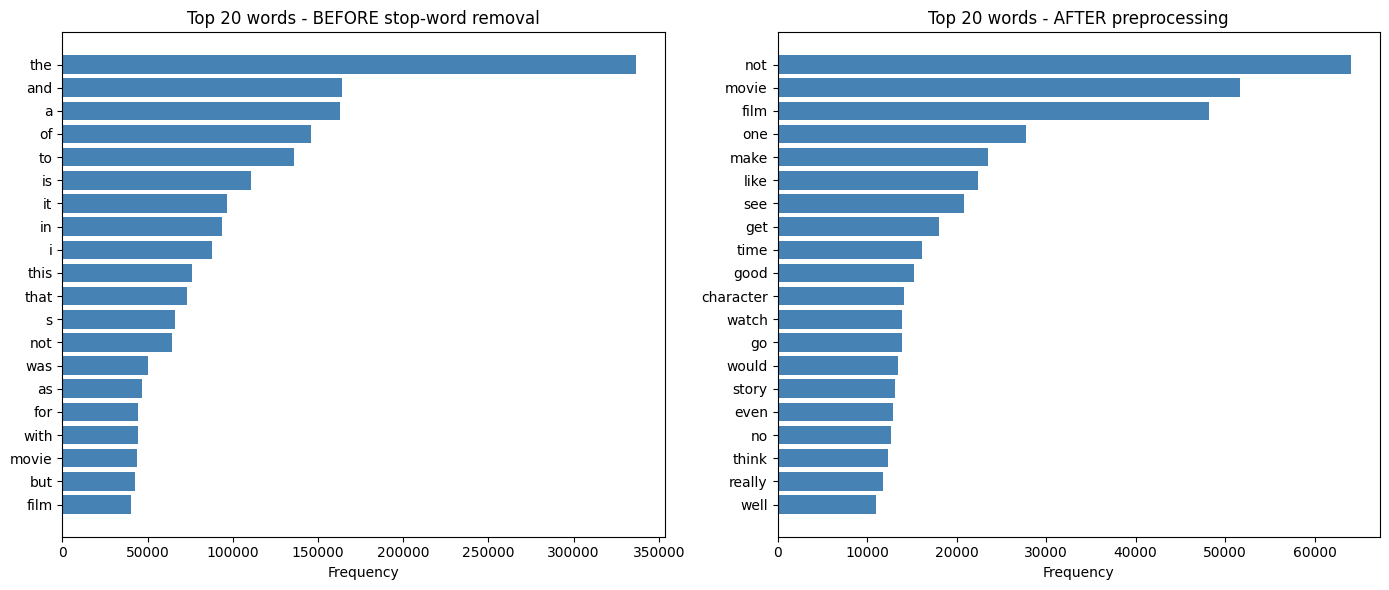

Tokens:   ['movie', 'not', 'good', 'complete', 'waste', 'time', 'money']
Bigrams:  [('movie', 'not'), ('not', 'good'), ('good', 'complete'), ('complete', 'waste'), ('waste', 'time'), ('time', 'money')]
Trigrams: [('movie', 'not', 'good'), ('not', 'good', 'complete'), ('good', 'complete', 'waste'), ('complete', 'waste', 'time'), ('waste', 'time', 'money')]
               Unigram               Bigram                 Trigram
1         not (64,113)    movie not (2,500)    movie ever see (447)
2       movie (51,713)     not even (2,247)  worst movie ever (386)
3        film (48,209)    could not (1,993)    not waste time (304)
4         one (27,748)     film not (1,831)     film ever see (230)
5        make (23,558)    look like (1,807)   movie ever make (209)
6        like (22,371)     not know (1,751)     make no sense (185)
7         see (20,799)  watch movie (1,553)   worst film ever (174)
8         get (18,017)    would not (1,505)   one worst movie (167)
9        time (16,175)     eve

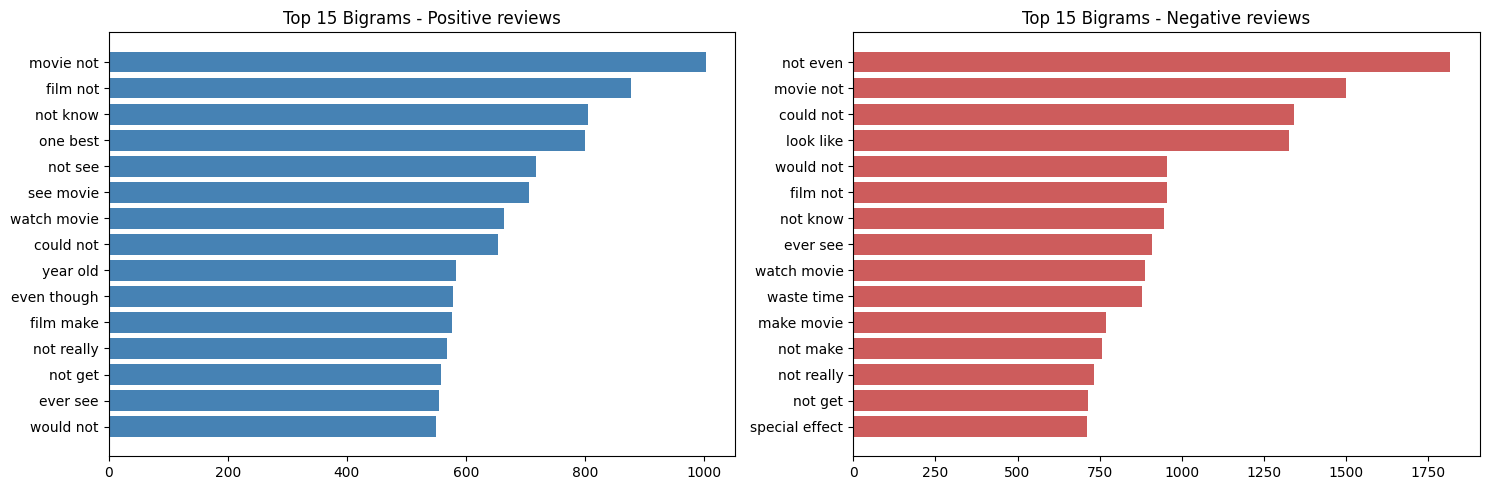

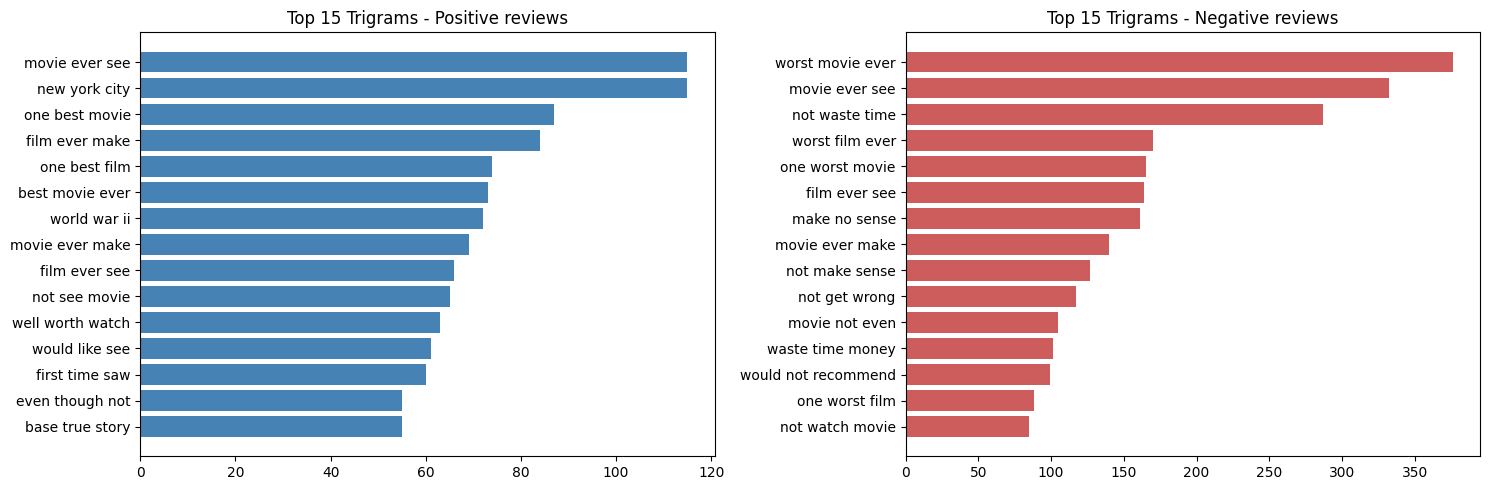


===== Characteristic Unigrams (min 100 reviews) =====
            Most POSITIVE        Most NEGATIVE
1      ratinggood (+2.86)    ratingbad (-3.86)
2        flawless (+2.43)  unwatchable (-3.07)
3        superbly (+2.24)          mst (-2.88)
4      perfection (+2.13)   incoherent (-2.84)
5     wonderfully (+1.99)      stinker (-2.80)
6          powell (+1.96)      unfunny (-2.67)
7    breathtaking (+1.82)    pointless (-2.46)
8         refresh (+1.81)       horrid (-2.41)
9      delightful (+1.77)    atrocious (-2.40)
10    beautifully (+1.73)        waste (-2.32)
11      underrate (+1.69)        worst (-2.31)
12         superb (+1.68)       drivel (-2.29)
13        sadness (+1.64)        lousy (-2.29)
14       timeless (+1.61)    laughable (-2.27)
15  unforgettable (+1.59)        awful (-2.25)

===== Characteristic Bigrams (min 100 reviews) =====
                  Most POSITIVE         Most NEGATIVE
1            well worth (+2.95)    worst film (-3.86)
2      definitely worth (+2.79)

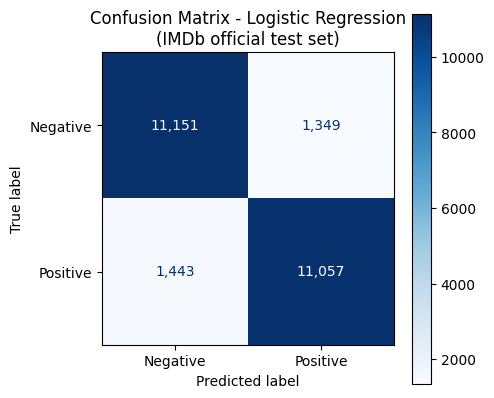

TN = 11,151 | FP = 1,349 | FN = 1,443 | TP = 11,057
              model  accuracy  precision  recall     f1
        Naive Bayes    0.8564     0.8841  0.8203 0.8510
Logistic Regression    0.8883     0.8913  0.8846 0.8879
        id                                                                                                                      review     true predicted  P(positive) result
 test_6868 I could not believe how terrible and boring this Hollywood remake was.It's so dreadful. It easily lands a place in my to... Negative  Negative        0.001      ✓
test_24016 I rented Boogie Nights last week and I could tell you, when I watched the film I had a blast. If you think that when you... Positive  Positive        0.983      ✓
 test_9668 First off, this movie is not near complete, my guess is that someone actually bothered to steal every other page of the ... Negative  Negative        0.001      ✓
test_13640 I watched this mini in the early eighties. Sam Waterson proved himself to

In [1]:
# Sentiment Analysis of IMDb Movie Reviews


# 0. Setup
import os, re, json
from collections import Counter, defaultdict
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)

USE_DRIVE = True
PROJECT_DIR = "/content/drive/MyDrive/NLP_Project"

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        os.makedirs(PROJECT_DIR, exist_ok=True)
        os.chdir(PROJECT_DIR)
    except Exception as e:
        print("Google Drive not used:", e)

for folder in ["data", "models", "results"]:
    os.makedirs(folder, exist_ok=True)

print("Working directory:", os.getcwd())


# 2. Dataset and Train/Test Separation
TRAIN_CSV, TEST_CSV = "data/imdb_train.csv", "data/imdb_test.csv"

if os.path.exists(TRAIN_CSV) and os.path.exists(TEST_CSV):
    train_df = pd.read_csv(TRAIN_CSV)
    test_df = pd.read_csv(TEST_CSV)
    print("Loaded saved CSV files from data/")
else:
    from datasets import load_dataset
    dataset = load_dataset("stanfordnlp/imdb")
    train_df = dataset["train"].to_pandas()
    test_df = dataset["test"].to_pandas()
    train_df.insert(0, "id", [f"train_{i}" for i in range(len(train_df))])
    test_df.insert(0, "id", [f"test_{i}" for i in range(len(test_df))])
    train_df[["id", "text", "label"]].to_csv(TRAIN_CSV, index=False)
    test_df[["id", "text", "label"]].to_csv(TEST_CSV, index=False)
    print("Downloaded from Hugging Face and saved to data/")

label_names = {0: "Negative", 1: "Positive"}
train_df["label_name"] = train_df["label"].map(label_names)
test_df["label_name"] = test_df["label"].map(label_names)

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Reviews appearing in both splits:", len(set(train_df["text"]) & set(test_df["text"])))
print(train_df.head())


# ----- Class distribution and review length -----
print("Train:", train_df["label"].value_counts().to_dict())
print("Test: ", test_df["label"].value_counts().to_dict())

train_df["num_words"] = train_df["text"].str.split().str.len()
print("\nReview length in words (training set):")
print(train_df["num_words"].describe().round(1).to_string())

print("===== Negative review =====")
print(train_df["text"][0])
print("\n===== Positive review =====")
print(train_df[train_df["label"] == 1]["text"].iloc[0])


# 3. Text Preprocessing
for resource in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

nltk_stop = set(stopwords.words("english"))
negations = {"not", "no", "nor", "never", "none", "nothing", "nobody", "neither", "without"}
STOP_WORDS = nltk_stop - negations

print("NLTK stop words:", len(nltk_stop))
print("Negation words in the NLTK list:", sorted(negations & nltk_stop))
print("'not' removed?", "not" in STOP_WORDS, "| 'the' removed?", "the" in STOP_WORDS)


# ----- Stemming compared with lemmatization -----
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

for w in ["movies", "loved", "loving", "acting", "boring", "studies", "better", "terrible"]:
    lemma = lemmatizer.lemmatize(w, pos="v")
    if lemma == w:
        lemma = lemmatizer.lemmatize(w, pos="n")
    print(f"{w:10s} → stem: {stemmer.stem(w):10s} lemma: {lemma}")

print("\n'better' with the adjective tag:", lemmatizer.lemmatize("better", pos="a"))


# ----- The preprocessing function -----
def convert_ratings(text):
    def replace(match):
        score = float(match.group(1))
        if score <= 4:
            return " ratingbad "
        elif score <= 6:
            return " ratingmid "
        return " ratinggood "
    return re.sub(r"\b(10|\d(?:\.\d)?)\s*/\s*10\b", replace, text)

@lru_cache(maxsize=None)
def lemmatize_word(word):
    lemma = lemmatizer.lemmatize(word, pos="v")
    if lemma == word:
        lemma = lemmatizer.lemmatize(word, pos="n")
    return lemma

def clean_text(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = convert_ratings(text)
    text = text.lower()
    text = text.replace("won't", "will not").replace("can't", "can not")
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def preprocess(text):
    tokens = clean_text(text).split()
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    tokens = [lemmatize_word(t) for t in tokens]
    return " ".join(tokens)

examples = [
    "I didn't like this movie!<br /><br />The acting was NOT good... 2/10",
    "Absolutely loved it. The actors were amazing. 9/10!",
    "It was released in 1967 and runs 2 hours.",
]
for t in examples:
    print("Before:", t)
    print("After: ", preprocess(t), "\n")

original = train_df["text"][0]
print("Real review before:\n", original[:400])
print("\nReal review after:\n", preprocess(original)[:400])

train_df["clean"] = train_df["text"].apply(preprocess)
test_df["clean"] = test_df["text"].apply(preprocess)
print(train_df[["text", "clean", "label_name"]].head())


# 4. Corpus Statistics
raw_tokens = [t for text in train_df["text"] for t in clean_text(text).split()]
clean_tokens = [t for text in train_df["clean"] for t in text.split()]
raw_counts, clean_counts = Counter(raw_tokens), Counter(clean_tokens)
hapax = sum(1 for c in clean_counts.values() if c == 1)

stats = pd.DataFrame([
    ["Training reviews", f"{len(train_df):,}"],
    ["Test reviews", f"{len(test_df):,}"],
    ["Positive / Negative (train)", "12,500 / 12,500"],
    ["Tokens before stop-word removal", f"{len(raw_tokens):,}"],
    ["Vocabulary before stop-word removal", f"{len(raw_counts):,}"],
    ["Tokens after preprocessing", f"{len(clean_tokens):,}"],
    ["Vocabulary after preprocessing", f"{len(clean_counts):,}"],
    ["Average tokens per review (before / after)", f"{len(raw_tokens)/len(train_df):.1f} / {len(clean_tokens)/len(train_df):.1f}"],
    ["Words appearing once (hapax)", f"{hapax:,} ({100*hapax/len(clean_counts):.1f}%)"],
], columns=["Statistic", "Value"])
stats.to_csv("results/corpus_statistics.csv", index=False)
print(stats.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, counts, title in [(axes[0], raw_counts, "Top 20 words - BEFORE stop-word removal"),
                          (axes[1], clean_counts, "Top 20 words - AFTER preprocessing")]:
    words, freqs = zip(*counts.most_common(20))
    ax.barh(words[::-1], freqs[::-1], color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.savefig("results/top_words.png", dpi=120)
plt.show()


# 5. N-gram Analysis
def get_ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

def top_ngrams(token_lists, n, k=15):
    counts = Counter()
    for tokens in token_lists:
        counts.update(get_ngrams(tokens, n))
    return [(" ".join(g), c) for g, c in counts.most_common(k)]

example = preprocess("This movie was not good, a complete waste of time and money.").split()
print("Tokens:  ", example)
print("Bigrams: ", get_ngrams(example, 2))
print("Trigrams:", get_ngrams(example, 3))

train_df["tokens"] = train_df["clean"].str.split()

table = pd.DataFrame({
    "Unigram": [f"{g} ({c:,})" for g, c in top_ngrams(train_df["tokens"], 1)],
    "Bigram":  [f"{g} ({c:,})" for g, c in top_ngrams(train_df["tokens"], 2)],
    "Trigram": [f"{g} ({c:,})" for g, c in top_ngrams(train_df["tokens"], 3)],
}, index=range(1, 16))
table.to_csv("results/top_ngrams.csv")
print(table.to_string())

pos_tokens = train_df[train_df.label == 1]["tokens"]
neg_tokens = train_df[train_df.label == 0]["tokens"]

for n, name in [(2, "Bigrams"), (3, "Trigrams")]:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, tokens, label, color in [(axes[0], pos_tokens, "Positive", "steelblue"),
                                     (axes[1], neg_tokens, "Negative", "indianred")]:
        grams, freqs = zip(*top_ngrams(tokens, n, 15))
        ax.barh(grams[::-1], freqs[::-1], color=color)
        ax.set_title(f"Top 15 {name} - {label} reviews")
    plt.tight_layout()
    plt.savefig(f"results/top_{name.lower()}_by_class.png", dpi=120)
    plt.show()


# ----- Characteristic N-grams of each class -----
def characteristic_ngrams(n, k=15, min_docs=100):
    pos_c, neg_c, doc_freq = Counter(), Counter(), Counter()
    for tokens in pos_tokens: pos_c.update(get_ngrams(tokens, n))
    for tokens in neg_tokens: neg_c.update(get_ngrams(tokens, n))
    for tokens in train_df["tokens"]:
        doc_freq.update(set(get_ngrams(tokens, n)))
    pos_total, neg_total = sum(pos_c.values()), sum(neg_c.values())

    scores = {}
    for g, df_count in doc_freq.items():
        if df_count < min_docs:
            continue
        p_pos = (pos_c[g] + 1) / pos_total
        p_neg = (neg_c[g] + 1) / neg_total
        scores[g] = np.log(p_pos / p_neg)

    ranked = sorted(scores.items(), key=lambda x: x[1])
    return pd.DataFrame({
        "Most POSITIVE": [f"{' '.join(g)} ({s:+.2f})" for g, s in ranked[::-1][:k]],
        "Most NEGATIVE": [f"{' '.join(g)} ({s:+.2f})" for g, s in ranked[:k]],
    }, index=range(1, k + 1))

for n, name, min_docs in [(1, "Unigrams", 100), (2, "Bigrams", 100), (3, "Trigrams", 30)]:
    df = characteristic_ngrams(n, min_docs=min_docs)
    df.to_csv(f"results/characteristic_{name.lower()}.csv")
    print(f"\n===== Characteristic {name} (min {min_docs} reviews) =====")
    print(df.to_string())


# 6. N-gram Language Model
def lm_sentences(text):
    text = re.sub(r"<[^>]+>", " . ", text).lower()
    text = text.replace("won't", "will not").replace("can't", "can not")
    text = re.sub(r"n't", " not", text)
    sentences = []
    for sent in re.split(r"[.!?]+", text):
        tokens = re.findall(r"[a-z]+", sent)
        if len(tokens) >= 2:
            sentences.append(tokens)
    return sentences

class NGramLanguageModel:
    def __init__(self):
        self.unigrams = Counter()
        self.bigrams = defaultdict(Counter)
        self.trigrams = defaultdict(Counter)

    def fit(self, texts):
        for text in texts:
            for sent in lm_sentences(text):
                words = ["<s>", "<s>"] + sent + ["</s>"]
                self.unigrams.update(words[2:])
                for i in range(2, len(words)):
                    self.bigrams[words[i-1]][words[i]] += 1
                    self.trigrams[(words[i-2], words[i-1])][words[i]] += 1
        return self

    def predict_next(self, context, k=5):
        context = re.sub(r"n't", " not", context.lower())
        words = ["<s>", "<s>"] + re.findall(r"[a-z]+", context)
        w1, w2 = words[-2], words[-1]
        if (w1, w2) in self.trigrams:
            counts, used = self.trigrams[(w1, w2)], "trigram"
        elif w2 in self.bigrams:
            counts, used = self.bigrams[w2], "bigram (backoff)"
        else:
            counts, used = self.unigrams, "unigram (backoff)"
        total = sum(counts.values())
        return [(w, c / total) for w, c in counts.most_common(k)], used

for s in lm_sentences("I loved this movie! The acting was great.<br /><br />Don't miss it."):
    print(s)

lm_train = train_df.sample(10000, random_state=SEED)
print("Sample labels:", lm_train["label"].value_counts().to_dict())

lm = NGramLanguageModel().fit(lm_train["text"])
print("Distinct words:", f"{len(lm.unigrams):,}")
print("Trigram contexts:", f"{len(lm.trigrams):,}")

prompts = ["this movie is", "one of the best", "the acting was", "i would not",
           "a complete waste of", "i highly", "the special effects", "worst movie i have"]

rows = []
for p in prompts:
    preds, used = lm.predict_next(p, k=5)
    rows.append({"prompt": p, "model used": used,
                 "top 5 next words": ", ".join(f"{w} ({pr:.2f})" for w, pr in preds)})
lm_results = pd.DataFrame(rows)
lm_results.to_csv("results/next_word_predictions.csv", index=False)
print(lm_results.to_string())

print("\nBackoff examples:")
for p in ["the purple elephant", "xyzabc"]:
    preds, used = lm.predict_next(p, k=5)
    print(f"  {p:20s} → {used:18s} {[w for w, _ in preds]}")

def generate(model, start, max_words=15):
    words = re.findall(r"[a-z]+", start.lower())
    for _ in range(max_words):
        preds, _ = model.predict_next(" ".join(words), k=3)
        if preds[0][0] == "</s>":
            break
        next_word = next((w for w, _ in preds if w != "</s>" and w not in words[-2:]), None)
        if next_word is None:
            break
        words.append(next_word)
    return " ".join(words)

for start in ["this movie is", "the plot", "i think", "the acting was"]:
    print(f"'{start}' → {generate(lm, start)}")


# ----- Positive and negative language models -----
lm_pos = NGramLanguageModel().fit(lm_train[lm_train.label == 1]["text"])
lm_neg = NGramLanguageModel().fit(lm_train[lm_train.label == 0]["text"])

rows = []
for p in ["the acting was", "this film is", "the story is", "i would", "the ending"]:
    rows.append({"prompt": p,
                 "Positive LM": ", ".join(w for w, _ in lm_pos.predict_next(p, k=5)[0]),
                 "Negative LM": ", ".join(w for w, _ in lm_neg.predict_next(p, k=5)[0])})
comparison_lm = pd.DataFrame(rows)
comparison_lm.to_csv("results/lm_positive_vs_negative.csv", index=False)
print(comparison_lm.to_string())


# ----- Perplexity -----
def perplexity(model, texts, k=1.0):
    V = len(model.unigrams) + 1
    log_prob, n = 0.0, 0
    for text in texts:
        for sent in lm_sentences(text):
            words = ["<s>"] + sent + ["</s>"]
            for prev, word in zip(words, words[1:]):
                count_pair = model.bigrams[prev][word] if prev in model.bigrams else 0
                count_prev = sum(model.bigrams[prev].values()) if prev in model.bigrams else 0
                log_prob += np.log((count_pair + k) / (count_prev + k * V))
                n += 1
    return np.exp(-log_prob / n)

test_sample = test_df["text"].sample(500, random_state=SEED)
for k in [1, 0.1, 0.01]:
    print(f"k = {k:<5} → perplexity = {perplexity(lm, test_sample, k=k):.1f}")


# 7. Bag of Words and Classification
docs = ["the movie was good", "the movie was not good", "good movie good acting"]
vec_toy = CountVectorizer(ngram_range=(1, 2))
print(pd.DataFrame(vec_toy.fit_transform(docs).toarray(),
                   columns=vec_toy.get_feature_names_out(), index=docs).to_string())


# ----- 7.2 Validation split -----
X_tr, X_val, y_tr, y_val = train_test_split(
    train_df["clean"], train_df["label"],
    test_size=0.10, stratify=train_df["label"], random_state=SEED)

print("Train part:", len(X_tr), "| Validation:", len(X_val), "| Test (not used):", len(test_df))

vec_check = CountVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.95)
X_tr_bow = vec_check.fit_transform(X_tr)
cells_total = X_tr_bow.shape[0] * X_tr_bow.shape[1]
print("BoW matrix:", X_tr_bow.shape)
print(f"Non-zero cells: {X_tr_bow.nnz:,} of {cells_total:,} ({100 * X_tr_bow.nnz / cells_total:.3f}%)")


# ----- 7.3 Model selection -----
def make_model(name):
    if name == "Naive Bayes":
        return MultinomialNB(alpha=1.0)
    return LogisticRegression(C=0.5, max_iter=2000, solver="liblinear")

experiments = []
for model_name in ["Naive Bayes", "Logistic Regression"]:
    for ngram_range in [(1, 1), (1, 2)]:
        vec = CountVectorizer(ngram_range=ngram_range, min_df=3, max_df=0.95)
        Xtr = vec.fit_transform(X_tr)
        Xva = vec.transform(X_val)
        model = make_model(model_name).fit(Xtr, y_tr)
        pred = model.predict(Xva)
        experiments.append({
            "model": model_name,
            "features": "unigrams" if ngram_range == (1, 1) else "unigrams + bigrams",
            "ngram_range": ngram_range,
            "vocab size": Xtr.shape[1],
            "val accuracy": round(accuracy_score(y_val, pred), 4),
            "val F1": round(f1_score(y_val, pred), 4),
        })

exp_df = pd.DataFrame(experiments).sort_values("val F1", ascending=False)
exp_df.drop(columns="ngram_range").to_csv("results/validation_experiments.csv", index=False)
print(exp_df.drop(columns="ngram_range").to_string(index=False))

best = exp_df.iloc[0]
BEST_MODEL, BEST_NGRAMS = best["model"], best["ngram_range"]
print(f"Selected: {BEST_MODEL} with {best['features']}")

vectorizer = CountVectorizer(ngram_range=BEST_NGRAMS, min_df=3, max_df=0.95)
X_train = vectorizer.fit_transform(train_df["clean"])
y_train = train_df["label"].values
classifier = make_model(BEST_MODEL).fit(X_train, y_train)
print("Final training matrix:", X_train.shape)


# 8. Evaluation on the Unseen Test Set
X_test = vectorizer.transform(test_df["clean"])
y_test = test_df["label"].values
y_pred = classifier.predict(X_test)
y_proba = classifier.predict_proba(X_test)[:, 1]

metrics = {
    "model": BEST_MODEL,
    "features": f"Bag of Words {BEST_NGRAMS}",
    "test size": int(len(y_test)),
    "accuracy":  round(accuracy_score(y_test, y_pred), 4),
    "precision": round(precision_score(y_test, y_pred), 4),
    "recall":    round(recall_score(y_test, y_pred), 4),
    "f1":        round(f1_score(y_test, y_pred), 4),
}
with open("results/test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
for k, v in metrics.items():
    print(f"{k:10s}: {v}")

print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(ax=ax, cmap="Blues", values_format=",")
ax.set_title(f"Confusion Matrix - {BEST_MODEL}\n(IMDb official test set)")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=120)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn:,} | FP = {fp:,} | FN = {fn:,} | TP = {tp:,}")

rows = []
for model_name in ["Naive Bayes", "Logistic Regression"]:
    p = make_model(model_name).fit(X_train, y_train).predict(X_test)
    rows.append({"model": model_name,
                 "accuracy":  round(accuracy_score(y_test, p), 4),
                 "precision": round(precision_score(y_test, p), 4),
                 "recall":    round(recall_score(y_test, p), 4),
                 "f1":        round(f1_score(y_test, p), 4)})
test_comparison = pd.DataFrame(rows)
test_comparison.to_csv("results/test_comparison.csv", index=False)
print(test_comparison.to_string(index=False))


# ----- 8.2 Individual predictions -----
results_df = test_df[["id", "text", "label_name"]].copy()
results_df["predicted"] = ["Positive" if p == 1 else "Negative" for p in y_pred]
results_df["P(positive)"] = y_proba.round(3)
results_df["correct"] = results_df["label_name"] == results_df["predicted"]
results_df.drop(columns="text").to_csv("results/test_predictions.csv", index=False)

sample = results_df.sample(12, random_state=SEED).copy()
sample["review"] = sample["text"].str.replace("<br />", " ").str[:120] + "..."
sample["result"] = sample["correct"].map({True: "✓", False: "✗"})
print(sample[["id", "review", "label_name", "predicted", "P(positive)", "result"]]
      .rename(columns={"label_name": "true"}).to_string(index=False))


# ----- 8.3 What the model learned -----
features = vectorizer.get_feature_names_out()
weights = classifier.coef_[0]
order = np.argsort(weights)

top_features = pd.DataFrame({
    "Strongest POSITIVE": [f"{features[i]} ({weights[i]:+.2f})" for i in order[::-1][:20]],
    "Strongest NEGATIVE": [f"{features[i]} ({weights[i]:+.2f})" for i in order[:20]],
}, index=range(1, 21))
top_features.to_csv("results/top_features.csv")
print(top_features.to_string())


# ----- 8.4 Error analysis -----
errors = results_df[~results_df["correct"]].copy()
errors["confidence"] = np.where(errors["predicted"] == "Positive",
                                errors["P(positive)"], 1 - errors["P(positive)"])
print(f"Errors: {len(errors):,} of {len(results_df):,}\n")

for title, true_label in [("FALSE POSITIVES: negative reviews predicted Positive", "Negative"),
                          ("FALSE NEGATIVES: positive reviews predicted Negative", "Positive")]:
    print("=" * 90 + "\n" + title + "\n" + "=" * 90)
    for _, r in errors[errors["label_name"] == true_label].nlargest(3, "confidence").iterrows():
        print(f"\n[{r['id']}] confidence: {r['confidence']:.3f}")
        print(r["text"].replace("<br />", " ")[:700], "...")
    print()

results_df["length"] = test_df["text"].str.split().str.len()
results_df["length group"] = pd.qcut(results_df["length"], 4,
                                     labels=["shortest 25%", "short", "long", "longest 25%"])
print("Accuracy by review length:")
print(results_df.groupby("length group", observed=True)["correct"].mean().round(4).to_string())

results_df["confidence"] = np.maximum(results_df["P(positive)"], 1 - results_df["P(positive)"])
print("\nMean confidence when correct:", round(results_df[results_df.correct]["confidence"].mean(), 3))
print("Mean confidence when wrong:  ", round(results_df[~results_df.correct]["confidence"].mean(), 3))

for review_id in ["test_21423", "test_13811"]:
    r = results_df[results_df["id"] == review_id].iloc[0]
    print(f"[{review_id}] true: {r['label_name']} | predicted: {r['predicted']} | P(positive): {r['P(positive)']}")
    print("Text:", r["text"].replace("<br />", " "))
    print("After preprocessing:", preprocess(r["text"]), "\n")


# 9. Save the Model and Demo
joblib.dump(vectorizer, "models/bow_vectorizer.joblib")
joblib.dump(classifier, "models/sentiment_classifier.joblib")
config = {"model": BEST_MODEL, "ngram_range": list(BEST_NGRAMS), "min_df": 3, "max_df": 0.95,
          "C": 0.5, "seed": SEED, "train_size": len(train_df), "test_accuracy": metrics["accuracy"]}
with open("models/config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Saved:", os.listdir("models"))

def predict_sentiment(text):
    vec = joblib.load("models/bow_vectorizer.joblib")
    model = joblib.load("models/sentiment_classifier.joblib")
    features = vec.transform([preprocess(text)])
    p_pos = model.predict_proba(features)[0, 1]
    label = "Positive" if p_pos >= 0.5 else "Negative"
    confidence = p_pos if label == "Positive" else 1 - p_pos
    return label, round(float(confidence), 3)

demo_reviews = [
    "An absolute masterpiece. The performances were stunning and I was moved to tears.",
    "Two hours of my life I will never get back. Terrible script and wooden acting.",
    "The movie was not good at all, very disappointing.",
    "I didn't expect much, but it did not disappoint. One of the best films this year!",
    "Great cast, beautiful visuals, but the story was boring and way too long.",
    "Oh wonderful, another sequel nobody asked for. Just brilliant.",
    "I'd give it 3/10.",
]
for r in demo_reviews:
    label, conf = predict_sentiment(r)
    print(f"{label:8s} ({conf:.1%})  ←  {r}")


# ----- to try your example ------
my_review = "The story was predictable, but the actors were fantastic and I enjoyed every minute."
# my_review = input("Write a movie review in English: ")

label, conf = predict_sentiment(my_review)
print(f"Review:     {my_review}")
print(f"Prediction: {label} (confidence {conf:.1%})")